# Punto 4 — Memoria asociativa (red de Hopfield moderna): parte computacional

**Energía.** Con $P$ patrones $x_\mu\in\{-1,+1\}^N$ (filas de $X\in\mathbb R^{P\times N}$) y estado continuo $\mathbf q\in\mathbb R^N$:

$$E(\mathbf q)=\frac12\sum_{i=1}^Nq_i^2-\frac1\beta\ln\left(\sum_{\mu=1}^P\exp\Bigl[\beta\sum_{i=1}^Nx_{\mu i}q_i\Bigr]\right).$$

**Gradiente.** Con los solapamientos $s_\mu=\sum_ix_{\mu i}q_i$ (es decir, $\mathbf s=X\mathbf q$) y los pesos
$$p_\mu=\frac{e^{\beta s_\mu}}{\sum_\nu e^{\beta s_\nu}}=\operatorname{softmax}(\beta X\mathbf q)_\mu,$$
se obtiene
$$\frac{\partial E}{\partial q_i}=q_i-\sum_{\mu=1}^Pp_\mu x_{\mu i},\qquad \nabla_{\mathbf q}E=\mathbf q-X^{\mathsf T}\operatorname{softmax}(\beta X\mathbf q).$$

**Regla de actualización** (descenso por gradiente):
$$\mathbf q^{(t+1)}=(1-\alpha)\,\mathbf q^{(t)}+\alpha\,X^{\mathsf T}\operatorname{softmax}\!\bigl(\beta X\mathbf q^{(t)}\bigr).$$

**Caso $\alpha=1$:**
$$\mathbf q^{(t+1)}=X^{\mathsf T}\operatorname{softmax}\!\bigl(\beta X\mathbf q^{(t)}\bigr)=\sum_\mu p_\mu\,x_\mu .$$
El nuevo estado es un promedio de los patrones almacenados, ponderado según su parecido con el estado actual.
- Si $\beta\to0$, los pesos se vuelven uniformes, $p_\mu\to1/P$, y el estado tiende al promedio de todos los patrones.
- Si $\beta\to\infty$, el softmax selecciona el patrón con mayor solapamiento, y la red lo recupera exactamente.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
rng = np.random.default_rng(2026)

## 1. Patrones almacenados

Cada letra es una imagen de $8\times8$ píxeles: `#` es un píxel activo ($+1$) y `.` uno inactivo ($-1$). Las imágenes se aplanan por filas en vectores de $N=64$ componentes, que forman las filas de $X$.

Calculamos también dos cantidades que serán importantes en el análisis:
- el solapamiento entre los patrones, $x_J\cdot x_H$;
- la distancia de Hamming $h$, el número de píxeles en que difieren.

X tiene tamaño (2, 64)
Solapamiento x_J · x_H = 0   (patrones ortogonales)
Distancia de Hamming entre J y H: h = 32 píxeles


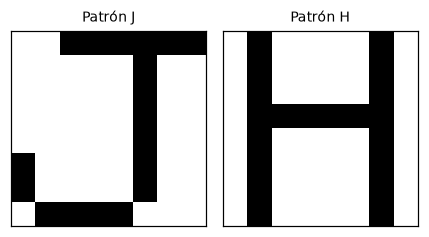

In [2]:
J_txt = ["..######",
         ".....#..",
         ".....#..",
         ".....#..",
         ".....#..",
         "#....#..",
         "#....#..",
         ".####..."]
H_txt = [".#....#.",
         ".#....#.",
         ".#....#.",
         ".######.",
         ".#....#.",
         ".#....#.",
         ".#....#.",
         ".#....#."]

to_vec = lambda rows: np.array([[1.0 if c == "#" else -1.0 for c in r] for r in rows]).ravel()
X = np.stack([to_vec(J_txt), to_vec(H_txt)])      # (P, N) = (2, 64)
P, N = X.shape
NOMBRES = ["J", "H"]

h_dist = int(np.sum(X[0] != X[1]))
print(f"X tiene tamaño {X.shape}")
print(f"Solapamiento x_J · x_H = {X[0] @ X[1]:.0f}   (patrones ortogonales)")
print(f"Distancia de Hamming entre J y H: h = {h_dist} píxeles")

def show(ax, v, title, cmap="Greys"):
    ax.imshow(v.reshape(8, 8), cmap=cmap, vmin=-1, vmax=1)
    ax.set_title(title, fontsize=9); ax.set_xticks([]); ax.set_yticks([])

fig, ax = plt.subplots(1, 2, figsize=(4, 2.2))
for k in range(P):
    show(ax[k], X[k], f"Patrón {NOMBRES[k]}")
plt.tight_layout(); plt.show()

## 2. Energía y dinámica de recuperación

Para evitar desbordamientos numéricos cuando $\beta s_\mu$ es grande, el softmax y el logaritmo de la suma de exponenciales se calculan restando el máximo:

$$\ln\sum_\mu e^{z_\mu}=z_{\max}+\ln\sum_\mu e^{z_\mu-z_{\max}} .$$

La dinámica usa $\alpha=1$. Se detiene cuando el cambio máximo entre iteraciones es menor que `TOL`, o al llegar a `T_MAX` iteraciones.

Como medida de calidad de la recuperación usamos dos cantidades:
- **Precisión binaria**: el porcentaje de píxeles de $\operatorname{sign}(\mathbf q)$ que coinciden con el patrón original. Un componente con $|q_i|<10^{-6}$ se considera **indefinido** (signo 0, gris en las figuras) y cuenta como error. Esto es necesario porque, como veremos en (c), algunos componentes tienden a cero; la iteración se detiene cuando aún valen $\sim10^{-10}$, y su signo es un residuo numérico sin significado.
- **Solapamiento continuo**: $m_\mu=\frac1N\,x_\mu\cdot\mathbf q$. Vale 1 si $\mathbf q=x_\mu$, y es el análogo de la magnetización en un sistema de espines.

In [3]:
ALPHA = 1.0
T_MAX = 5000
TOL = 1e-10

def logsumexp(z):
    zmax = np.max(z)
    return zmax + np.log(np.sum(np.exp(z - zmax)))

def softmax(z):
    e = np.exp(z - np.max(z))
    return e / e.sum()

def energy(q, beta):
    return 0.5 * q @ q - logsumexp(beta * (X @ q)) / beta

def grad_energy(q, beta):
    return q - X.T @ softmax(beta * (X @ q))

def recall(q0, beta, alpha=ALPHA, t_max=T_MAX, tol=TOL):
    # Itera q <- q - alpha * grad E(q). Devuelve el estado final, la energía por iteración y el número de iteraciones.
    q = q0.astype(float).copy()
    energies = [energy(q, beta)]
    for t in range(1, t_max + 1):
        q_new = q - alpha * grad_energy(q, beta)
        energies.append(energy(q_new, beta))
        converged = np.max(np.abs(q_new - q)) < tol
        q = q_new
        if converged:
            break
    return q, np.array(energies), t

def perturb(x, frac, rng):
    # Invierte el signo de una fracción 'frac' de los píxeles, elegidos al azar sin repetición.
    q0 = x.copy()
    idx = rng.choice(N, size=int(round(frac * N)), replace=False)
    q0[idx] *= -1
    return q0

SIGN_TOL = 1e-6

def binarize(q):
    return np.where(np.abs(q) < SIGN_TOL, 0.0, np.sign(q))

def binary_accuracy(q, x):
    return 100 * np.mean(binarize(q) == x)

def overlaps(q):
    return X @ q / N

# Verificación del gradiente analítico con diferencias finitas
q_test, beta_test, eps = rng.normal(size=N), 0.07, 1e-6
g_fd = np.array([(energy(q_test + eps * e, beta_test) - energy(q_test - eps * e, beta_test)) / (2 * eps)
                 for e in np.eye(N)])
print(f"max|grad analítico - grad numérico| = {np.max(np.abs(grad_energy(q_test, beta_test) - g_fd)):.1e}")

max|grad analítico - grad numérico| = 4.0e-09


## 3. Experimento (a): recuperación de un patrón perturbado

Tomamos el patrón J y le invertimos el 25 % de los píxeles. Luego dejamos evolucionar la red con $\beta=0.1$. Mostramos el estado continuo final $\mathbf q$ y su versión binaria $\operatorname{sign}(\mathbf q)$.

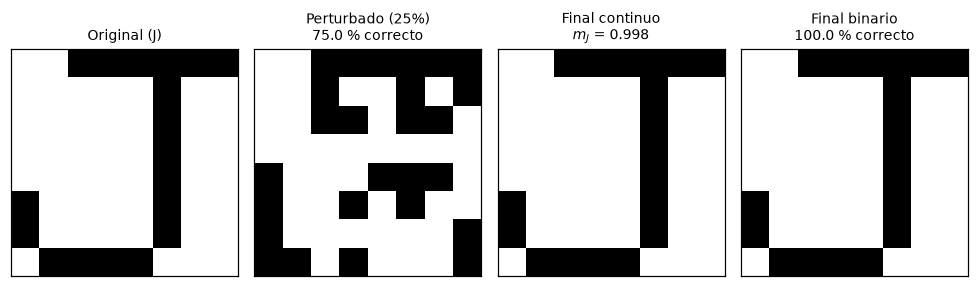

Iteraciones hasta convergencia: 8
Solapamientos finales: m_J = 0.9983,  m_H = 0.0017
Rango del estado continuo: [-1.0000, 1.0000]


In [4]:
BETA_A, FRAC_A = 0.1, 0.25
q0 = perturb(X[0], FRAC_A, rng)
qf, E_hist, n_it = recall(q0, BETA_A)

fig, ax = plt.subplots(1, 4, figsize=(9, 2.6))
show(ax[0], X[0], "Original (J)")
show(ax[1], q0, f"Perturbado ({FRAC_A:.0%})\n{binary_accuracy(q0, X[0]):.1f} % correcto")
show(ax[2], qf, f"Final continuo\n$m_J$ = {overlaps(qf)[0]:.3f}")
show(ax[3], binarize(qf), f"Final binario\n{binary_accuracy(qf, X[0]):.1f} % correcto")
plt.tight_layout(); plt.show()

print(f"Iteraciones hasta convergencia: {n_it}")
print(f"Solapamientos finales: m_J = {overlaps(qf)[0]:.4f},  m_H = {overlaps(qf)[1]:.4f}")
print(f"Rango del estado continuo: [{qf.min():.4f}, {qf.max():.4f}]")

## 4. Experimento (b): efecto del porcentaje de píxeles perturbados

Para cada porcentaje de 0 % a 70 % generamos 200 perturbaciones aleatorias de J. Luego medimos tres cosas:
- la precisión binaria media;
- la fracción de ensayos con recuperación perfecta (100 % de los píxeles);
- la fracción de ensayos en que la red cae en el otro patrón, H.

Usamos tres valores de $\beta$, por encima de un valor crítico que se identifica en el experimento (c).

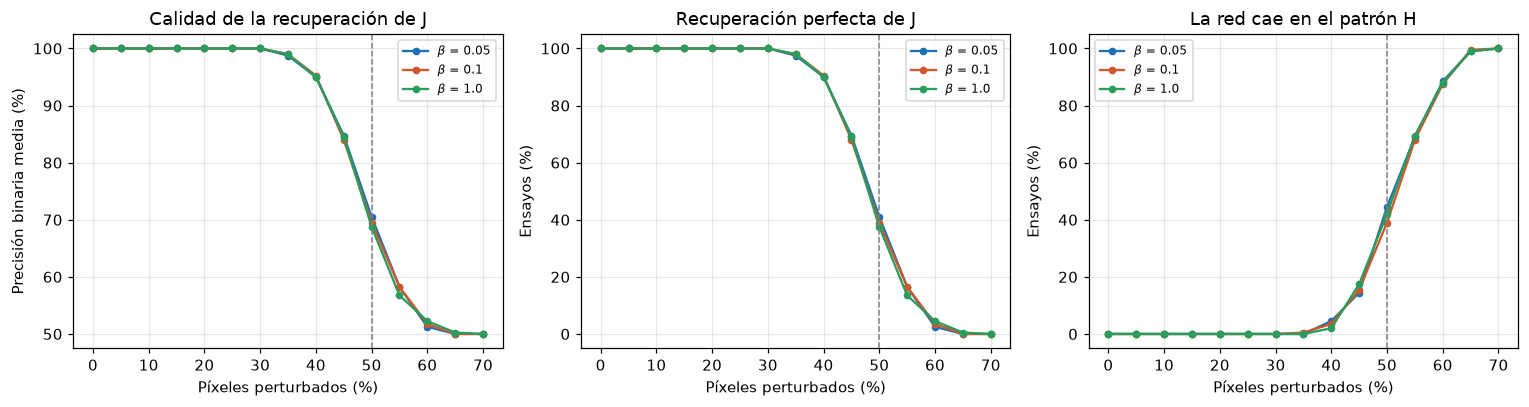

Porcentaje perturbado:         0     5    10    15    20    25    30    35    40    45    50    55    60    65    70
beta = 0.05  perfecta(%): 100.0 100.0 100.0 100.0 100.0 100.0 100.0  97.5  90.0  69.5  41.0  16.5   2.5   0.0   0.0
beta = 0.1   perfecta(%): 100.0 100.0 100.0 100.0 100.0 100.0 100.0  98.0  90.5  68.0  39.0  16.5   3.5   0.0   0.0
beta = 1.0   perfecta(%): 100.0 100.0 100.0 100.0 100.0 100.0 100.0  98.0  90.0  69.0  37.5  13.5   4.5   0.5   0.0


In [5]:
fracs = np.arange(0, 0.71, 0.05)
betas_b = [0.05, 0.1, 1.0]
N_TRIALS = 200

res_b = {}
for beta in betas_b:
    acc_mean, perfect, to_H = [], [], []
    for f in fracs:
        accs, hits_H = [], []
        for _ in range(N_TRIALS):
            qf_ = recall(perturb(X[0], f, rng), beta)[0]
            accs.append(binary_accuracy(qf_, X[0]))
            hits_H.append(binary_accuracy(qf_, X[1]) == 100)
        accs = np.array(accs)
        acc_mean.append(accs.mean()); perfect.append(np.mean(accs == 100)); to_H.append(np.mean(hits_H))
    res_b[beta] = dict(acc=np.array(acc_mean), perfect=np.array(perfect), to_H=np.array(to_H))

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for beta, c in zip(betas_b, ["#1f6fb4", "#d1562b", "#2a9d5c"]):
    ax[0].plot(100 * fracs, res_b[beta]["acc"], "o-", color=c, ms=4, label=rf"$\beta$ = {beta}")
    ax[1].plot(100 * fracs, 100 * res_b[beta]["perfect"], "o-", color=c, ms=4, label=rf"$\beta$ = {beta}")
    ax[2].plot(100 * fracs, 100 * res_b[beta]["to_H"], "o-", color=c, ms=4, label=rf"$\beta$ = {beta}")
ax[0].set(xlabel="Píxeles perturbados (%)", ylabel="Precisión binaria media (%)", title="Calidad de la recuperación de J")
ax[1].set(xlabel="Píxeles perturbados (%)", ylabel="Ensayos (%)", title="Recuperación perfecta de J")
ax[2].set(xlabel="Píxeles perturbados (%)", ylabel="Ensayos (%)", title="La red cae en el patrón H")
for a in ax:
    a.axvline(50, color="gray", ls="--", lw=1); a.grid(alpha=0.3); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

print("Porcentaje perturbado:     " + " ".join(f"{100*f:5.0f}" for f in fracs))
for beta in betas_b:
    print(f"beta = {beta:<4}  perfecta(%): " + " ".join(f"{100*v:5.1f}" for v in res_b[beta]["perfect"]))

## 5. Experimento (c): efecto de $\beta$

**Predicción teórica del valor crítico.** Como J y H son ortogonales, después de la primera iteración el estado queda en la forma $\mathbf q=a\,x_J+b\,x_H$ con $a+b=1$. Definimos la diferencia de pesos $m=a-b$. La regla con $\alpha=1$ da
$$m^{(t+1)}=p_J-p_H=\tanh\!\left(\frac{\beta}{2}(s_J-s_H)\right)=\tanh\bigl(\beta\,h\,m^{(t)}\bigr),$$
donde $h=32$ es la distancia de Hamming entre J y H. Es la misma ecuación de autoconsistencia que la magnetización del modelo de Ising en campo medio, $m=\tanh(\beta Jz\,m)$, y por tanto tiene un **punto crítico** en
$$\beta_c=\frac1h=\frac1{32}\approx0.031 .$$
- **Para $\beta<\beta_c$** el único punto fijo es $m=0$: la red olvida cuál patrón tenía y converge al promedio $\tfrac12(x_J+x_H)$.
- **Para $\beta>\beta_c$** aparecen dos puntos fijos estables $\pm m^*$, uno cerca de cada patrón: son los estados de **recuperación**.

Partimos del mismo estado perturbado (25 % de los píxeles de J invertidos) y lo dejamos evolucionar con distintos $\beta$.

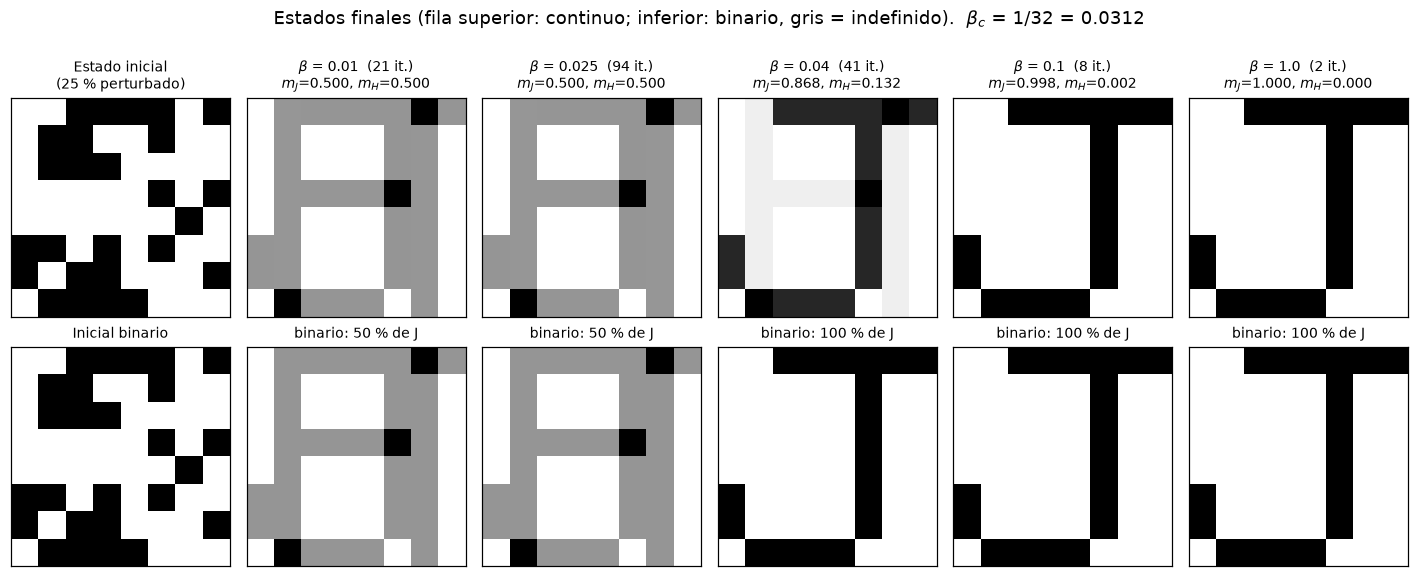

In [6]:
beta_c = 1 / h_dist
q0_c = perturb(X[0], 0.25, rng)
betas_c = [0.01, 0.025, 0.04, 0.1, 1.0]

fig, ax = plt.subplots(2, len(betas_c) + 1, figsize=(13, 5.4))
show(ax[0, 0], q0_c, "Estado inicial\n(25 % perturbado)")
show(ax[1, 0], binarize(q0_c), "Inicial binario")
finals_c = {}
for k, beta in enumerate(betas_c, start=1):
    qf_, E_, it_ = recall(q0_c, beta)
    finals_c[beta] = (qf_, E_, it_)
    mJ, mH = overlaps(qf_)
    show(ax[0, k], qf_, rf"$\beta$ = {beta}  ({it_} it.)" + f"\n$m_J$={mJ:.3f}, $m_H$={mH:.3f}")
    show(ax[1, k], binarize(qf_), f"binario: {binary_accuracy(qf_, X[0]):.0f} % de J")
plt.suptitle(rf"Estados finales (fila superior: continuo; inferior: binario, gris = indefinido).  $\beta_c$ = 1/{h_dist} = {beta_c:.4f}", y=1.0)
plt.tight_layout(); plt.show()

**Evolución de la energía.** La gráfica izquierda muestra $E(\mathbf q^{(t)})$ para cada $\beta$. La derecha muestra la distancia a la energía final, $E(\mathbf q^{(t)})-E_\infty$, en escala logarítmica, que permite ver la velocidad de convergencia.

beta = 0.01 : E_0 =   -52.926  ->  E_final =  -85.3147   iteraciones =   21   máximo aumento entre pasos = 0.0e+00
beta = 0.025: E_0 =   -13.646  ->  E_final =  -43.7259   iteraciones =   94   máximo aumento entre pasos = 7.1e-15
beta = 0.04 : E_0 =    -5.316  ->  E_final =  -34.4214   iteraciones =   41   máximo aumento entre pasos = 4.3e-14
beta = 0.1  : E_0 =    -0.270  ->  E_final =  -32.0168   iteraciones =    8   máximo aumento entre pasos = 2.1e-14
beta = 1.0  : E_0 =     0.000  ->  E_final =  -32.0000   iteraciones =    2   máximo aumento entre pasos = 1.4e-14


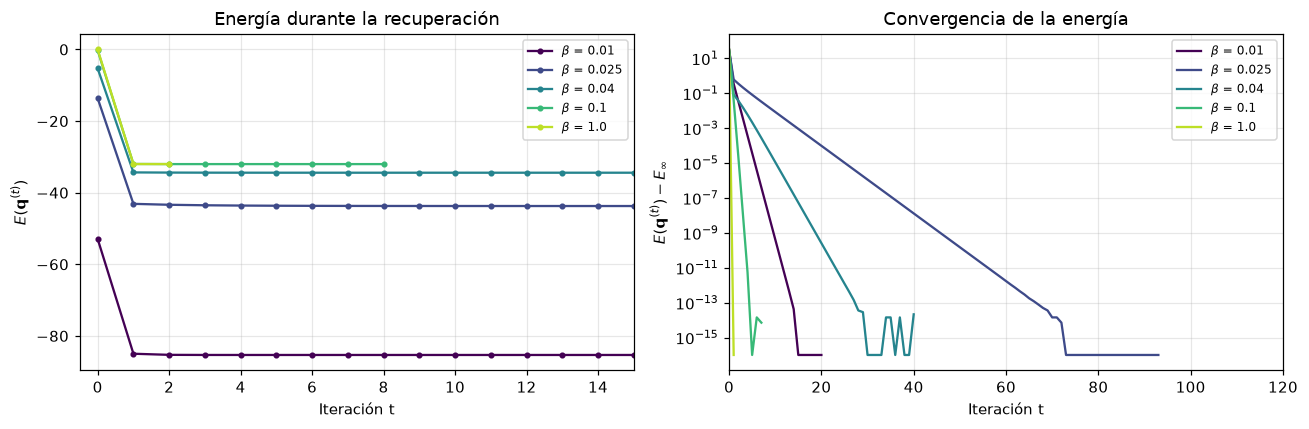

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
colors = plt.cm.viridis(np.linspace(0, 0.9, len(betas_c)))
for beta, c in zip(betas_c, colors):
    E_ = finals_c[beta][1]
    ax[0].plot(E_, "o-", ms=3, color=c, label=rf"$\beta$ = {beta}")
    dE = E_[:-1] - E_[-1]
    ax[1].semilogy(np.arange(len(dE)), np.maximum(dE, 1e-16), color=c, label=rf"$\beta$ = {beta}")
    print(f"beta = {beta:<5}: E_0 = {E_[0]:9.3f}  ->  E_final = {E_[-1]:9.4f}   "
          f"iteraciones = {len(E_)-1:4d}   máximo aumento entre pasos = {max(0, np.max(np.diff(E_))):.1e}")
ax[0].set(xlabel="Iteración t", ylabel=r"$E(\mathbf{q}^{(t)})$", title="Energía durante la recuperación", xlim=(-0.5, 15))
ax[1].set(xlabel="Iteración t", ylabel=r"$E(\mathbf{q}^{(t)})-E_\infty$", title="Convergencia de la energía", xlim=(0, 120))
for a in ax:
    a.grid(alpha=0.3); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Diagrama de bifurcación.** Barremos $\beta$ desde $0.005$ hasta $1$ y registramos los solapamientos finales $m_J=a$ y $m_H=b$, junto con el número de iteraciones hasta converger.

La curva teórica sale de resolver $m^*=\tanh(\beta h\,m^*)$, con $a=\tfrac12(1+m^*)$ y $b=\tfrac12(1-m^*)$.

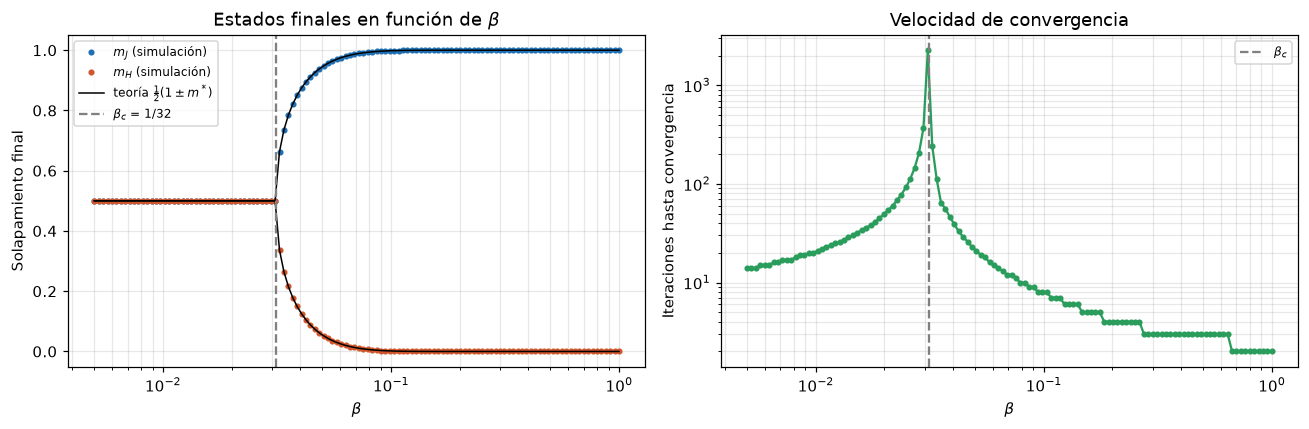

Máximo de iteraciones: 2269 en beta = 0.0310   (beta_c = 0.0312)
Error máximo simulación vs. teoría en m_J: 7.0e-09


In [8]:
betas_scan = np.logspace(np.log10(0.005), 0, 120)
mJ_scan, mH_scan, it_scan = [], [], []
for beta in betas_scan:
    qf_, _, it_ = recall(q0_c, beta)
    mJ, mH = overlaps(qf_)
    mJ_scan.append(mJ); mH_scan.append(mH); it_scan.append(it_)

def m_star(beta):
    if beta * h_dist <= 1:
        return 0.0
    return brentq(lambda m: m - np.tanh(beta * h_dist * m), 1e-9, 1.0)

m_th = np.array([m_star(b) for b in betas_scan])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].semilogx(betas_scan, mJ_scan, "o", ms=3, color="#1f6fb4", label=r"$m_J$ (simulación)")
ax[0].semilogx(betas_scan, mH_scan, "o", ms=3, color="#d1562b", label=r"$m_H$ (simulación)")
ax[0].semilogx(betas_scan, (1 + m_th) / 2, "k-", lw=1, label=r"teoría $\frac{1}{2}(1\pm m^*)$")
ax[0].semilogx(betas_scan, (1 - m_th) / 2, "k-", lw=1)
ax[0].axvline(beta_c, color="gray", ls="--", label=rf"$\beta_c$ = 1/{h_dist}")
ax[0].set(xlabel=r"$\beta$", ylabel="Solapamiento final", title="Estados finales en función de $\\beta$")
ax[1].loglog(betas_scan, it_scan, "o-", ms=3, color="#2a9d5c")
ax[1].axvline(beta_c, color="gray", ls="--", label=r"$\beta_c$")
ax[1].set(xlabel=r"$\beta$", ylabel="Iteraciones hasta convergencia", title="Velocidad de convergencia")
for a in ax:
    a.grid(alpha=0.3, which="both"); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

k_max = int(np.argmax(it_scan))
print(f"Máximo de iteraciones: {it_scan[k_max]} en beta = {betas_scan[k_max]:.4f}   (beta_c = {beta_c:.4f})")
print(f"Error máximo simulación vs. teoría en m_J: {np.max(np.abs(np.array(mJ_scan) - (1 + m_th) / 2)):.1e}")

## 6. Análisis de resultados

En el experimento (a), con $\beta=0.1$ y el 25 % de los píxeles de J invertidos, la red recupera J en 8 iteraciones: el estado continuo final tiene un solapamiento $m_J=0.998$ y su versión binaria coincide con J en el 100 % de los píxeles. Esto se debe a que, con $\alpha=1$, el nuevo estado $\mathbf q^{(t+1)}=\sum_\mu p_\mu x_\mu$ se construye a partir de los patrones almacenados y no del estado ruidoso, de modo que el ruido desaparece desde la primera iteración.

En el experimento (b), la recuperación es perfecta hasta un 30 % de píxeles perturbados, todavía supera el 90 % con un 40 %, baja a cerca del 40 % con la mitad de la imagen perturbada y es casi nula desde el 65 %. Las curvas para $\beta=0.05$, $0.1$ y $1$ prácticamente coinciden, porque lo que decide el resultado es a cuál patrón se parece más el estado inicial ($s_J$ frente a $s_H$), y esa frontera está cerca del 50 %. Cuando la red falla, cae en H; por eso la precisión media no baja del 50 %, ya que J y H coinciden en la mitad de los píxeles.

En el experimento (c), $\beta$ determina si la red distingue los patrones. Como J y H son ortogonales, la diferencia de pesos $m=a-b$ cumple $m^{(t+1)}=\tanh(\beta h\,m^{(t)})$ con $h=32$, la misma ecuación del modelo de Ising en campo medio, con valor crítico $\beta_c=1/32\approx0.031$. Para $\beta<\beta_c$ (0.01 y 0.025) la red converge al promedio de J y H, con $m_J=m_H=0.5$, y olvida cuál letra se le presentó. Para $\beta>\beta_c$ la red elige el patrón más parecido: con $\beta=0.04$ la elección todavía es parcial ($m_J=0.87$), con $\beta=0.1$ ya es casi exacta ($m_J=0.998$) y con $\beta=1$ recupera J exactamente en dos iteraciones. La simulación coincide con la predicción teórica, y cerca de $\beta_c$ la convergencia se vuelve muy lenta (más de 2000 iteraciones), como ocurre en las transiciones de fase. La energía disminuye en cada iteración para todos los valores de $\beta$, con la mayor caída en la primera iteración.

En conclusión, $\beta$ funciona como el inverso de una temperatura: con $\beta$ pequeño la red mezcla los recuerdos y no los distingue, y con $\beta$ grande recupera el patrón más cercano con rapidez y precisión.